# Is Tolles–Lawson enough for an in-cabin magnetometer?

**QuASI Open Notebook 01** · Data: DAF-MIT AIA open flight data for magnetic navigation [1], flight 1002

Mounting a magnetometer on a tail stinger far from the aircraft is the textbook solution for airborne magnetics. But stingers are expensive, draggy and impractical on many platforms (UAS, transport aircraft, retrofit installations). The obvious alternative is to put the sensor **inside the cabin** and compensate.

This notebook asks three practical questions:

1. How much aircraft interference do in-cabin magnetometers actually see, compared to a stinger?
2. How well does a classic **Tolles–Lawson (TL)** calibration, flown as a high-altitude calibration box, transfer to low-altitude survey lines?
3. How much more do we gain by fitting TL *with* a reference signal and by adding aircraft telemetry (currents, voltages, attitude rates) as extra regressors?

The flight carries a compensated tail-stinger magnetometer (`mag_1_c`), which we use as the reference "truth", and three uncompensated in-cabin scalar sensors (`mag_3_uc`, `mag_4_uc`, `mag_5_uc`) plus three fluxgate vector magnetometers (`flux_b/c/d`).

In [1]:
import os, numpy as np, matplotlib.pyplot as plt
import quasimag as q
q.style()
DATA = os.environ.get("MAGNAV_DATA", "data")
D = q.load_flight(f"{DATA}/Flt1002-train.h5")
line = D["tie_line"]
print(f"{len(line):,} samples at 10 Hz  ({len(line)/36000:.1f} h of flight)")

207,578 samples at 10 Hz  (5.8 h of flight)


## 1. The flight

Flight 1002 contains a high-altitude (~3.2 km) calibration box (line 1002.02), followed by low-altitude (~300 m) survey and tie lines. We hold out six low-altitude lines for testing.

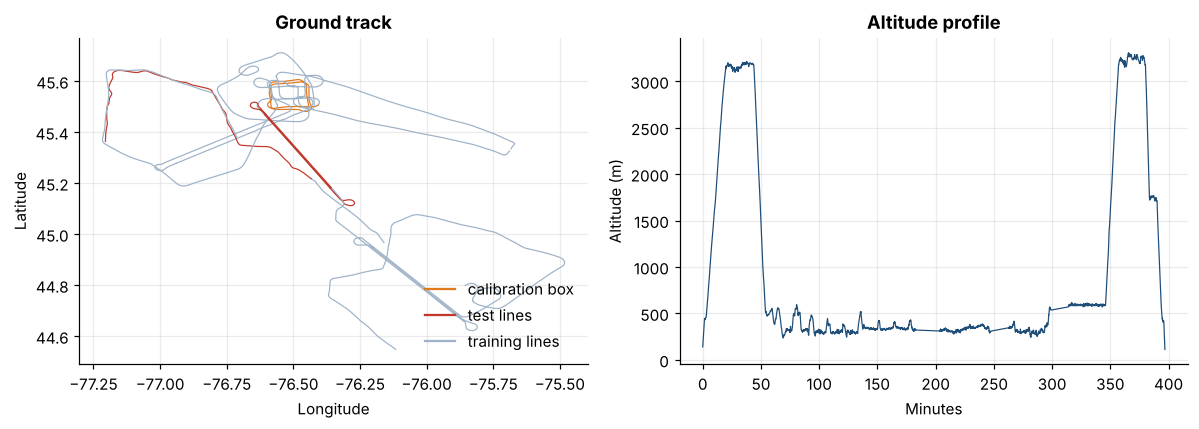

In [2]:
CAL = 1002.02
TEST = [1367, 1368, 1369, 1002.16, 1002.06, 1002.07]
TRAIN = [l for l in np.unique(line) if l not in TEST + [1002.01, 1002.21]]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for l in np.unique(line):
    s = line == l
    c = "#e07a1f" if l == CAL else ("#c0392b" if l in TEST else "#9fb3c8")
    ax[0].plot(D["lon"][s], D["lat"][s], c=c, lw=.8)
ax[0].set(xlabel="Longitude", ylabel="Latitude", title="Ground track")
o = np.argsort(D["tt"])
ax[1].plot((D["tt"][o]-D["tt"].min())/60, D["alt"][o], c="#1f4e79", lw=.8)
ax[1].set(xlabel="Minutes", ylabel="Altitude (m)", title="Altitude profile")
from matplotlib.lines import Line2D
ax[0].legend([Line2D([], [], c=c) for c in ["#e07a1f", "#c0392b", "#9fb3c8"]],
             ["calibration box", "test lines", "training lines"], loc="lower right")
plt.tight_layout()

## 2. How dirty is the cabin?

The difference between each in-cabin sensor and the stinger reference is (almost entirely) aircraft interference: the sensors are only metres apart, so geology and diurnal variation cancel. A linear detrend removes the slowly varying level offset.

mag_3_uc: median  366.5 nT
mag_4_uc: median  122.7 nT
mag_5_uc: median   34.7 nT


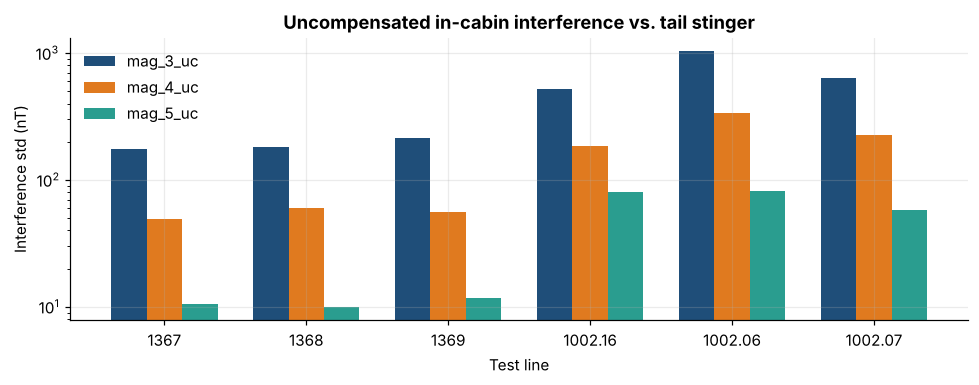

In [3]:
MAGS = ["mag_3_uc", "mag_4_uc", "mag_5_uc"]
def resid(sig, l):
    s = line == l
    return q.detrend_std(sig[s] - D["mag_1_c"][s])
raw = {m: [resid(D[m], l) for l in TEST] for m in MAGS}
fig, ax = plt.subplots(figsize=(9, 3.6))
w = .25
for i, m in enumerate(MAGS):
    ax.bar(np.arange(len(TEST)) + (i-1)*w, raw[m], w, label=m)
ax.set_xticks(range(len(TEST)), [str(l) for l in TEST]); ax.set_yscale("log")
ax.set(ylabel="Interference std (nT)", xlabel="Test line", title="Uncompensated in-cabin interference vs. tail stinger")
ax.legend(); plt.tight_layout()
for m in MAGS: print(f"{m}: median {np.median(raw[m]):6.1f} nT")

Interference ranges from ~10 nT (`mag_5`) to hundreds of nT (`mag_3`). For context, useful magnetic navigation needs map-matching residuals of a few nT to a few tens of nT, and detecting a small ferrous target needs well under 1 nT.

## 3. Classic Tolles–Lawson from the calibration box

The TL model [2], [3] expresses the aircraft field as a linear function of the direction cosines $c_i$ of the Earth's field (from a fluxgate), the total field $B_t$, and their rates:

$$ B_{\text{ac}} = \underbrace{\sum_i a_i c_i}_{\text{permanent}} + \underbrace{B_t \sum_{i\le j} b_{ij} c_i c_j}_{\text{induced}} + \underbrace{B_t \sum_{i,j} e_{ij} c_i \dot c_j}_{\text{eddy}} $$

Two identities ($\sum c_i^2 = 1$ and $\sum c_i \dot c_i = 0$) make two columns redundant, giving 16 terms. The classic recipe fits these on **band-passed** (0.1–0.9 Hz) calibration-box data, where the aircraft's manoeuvres dominate and geology is weak.

In [4]:
def classic_tl(mag, flux):
    A = q.tl_matrix(*(D[f"flux_{flux}_{a}"] for a in "xyz"))
    cal = line == CAL
    coef = q.tl_fit(A[cal], D[mag][cal])
    return q.tl_apply(A, D[mag], coef)

def resid_band(sig, l, lo=.1, hi=.9):
    s = line == l
    return np.std(q.bpf(sig[s] - D["mag_1_c"][s], lo=lo, hi=hi)[200:-200])

print("Residual std on test lines in the 0.1-0.9 Hz fitting band (nT)\n")
print(f"{'sensor':10s}{'flux':>6s}{'raw':>8s}{'TL':>8s}")
classic = {}
for m in MAGS:
    for fl in "bcd":
        c = classic_tl(m, fl)
        r0 = np.median([resid_band(D[m], l) for l in TEST])
        r1 = np.median([resid_band(c, l) for l in TEST])
        classic[(m, fl)] = c
        print(f"{m:10s}{fl:>6s}{r0:8.2f}{r1:8.2f}")

Residual std on test lines in the 0.1-0.9 Hz fitting band (nT)

sensor      flux     raw      TL
mag_3_uc       b   99.11    5.35


mag_3_uc       c   99.11    5.48
mag_3_uc       d   99.11    5.17


mag_4_uc       b   30.24    3.69
mag_4_uc       c   30.24    3.61


mag_4_uc       d   30.24    3.76
mag_5_uc       b    5.56    1.11


mag_5_uc       c    5.56    1.13
mag_5_uc       d    5.56    1.15


Inside the fitting band, classic TL removes 80–95 % of the interference, and the choice of fluxgate hardly matters. The more honest test is the full bandwidth, which includes slow, heading-dependent errors:

In [5]:
print(f"{'sensor':10s}{'raw':>8s}{'classic TL':>12s}   (full band, detrended, median of test lines, nT)")
for m in MAGS:
    best = min("bcd", key=lambda fl: np.median([resid(classic[(m, fl)], l) for l in TEST]))
    print(f"{m:10s}{np.median(raw[m]):8.1f}{np.median([resid(classic[(m, best)], l) for l in TEST]):12.1f}   (flux_{best})")

sensor         raw  classic TL   (full band, detrended, median of test lines, nT)
mag_3_uc     366.5        23.7   (flux_b)
mag_4_uc     122.7        15.6   (flux_b)


mag_5_uc      34.7         4.2   (flux_b)


**Take-away 1:** a 20-minute calibration box flown at 3 km transfers surprisingly well to 300 m survey lines, cutting full-band interference by ~85–95 %. But compare the in-band (1–5 nT) and full-band (4–24 nT) residuals: **most of what is left lives below 0.1 Hz**, where the band-passed fit has no leverage and where in-cabin sources that TL does not model (electrical loads, servos, heaters) operate.

## 4. Supervised TL and TL + telemetry

If a reference is available on some lines (as here, or from a known map), we can fit TL **directly to the interference** $y = B_{\text{cabin}} - B_{\text{ref}}$ on all training lines at full bandwidth. We then add the aircraft's own telemetry (14 currents, 17 voltages, attitude and attitude rates) as extra ridge-regularised regressors, first as recorded, then **low-pass filtered at 0.5 Hz**. Everything is evaluated on lines the models never saw.

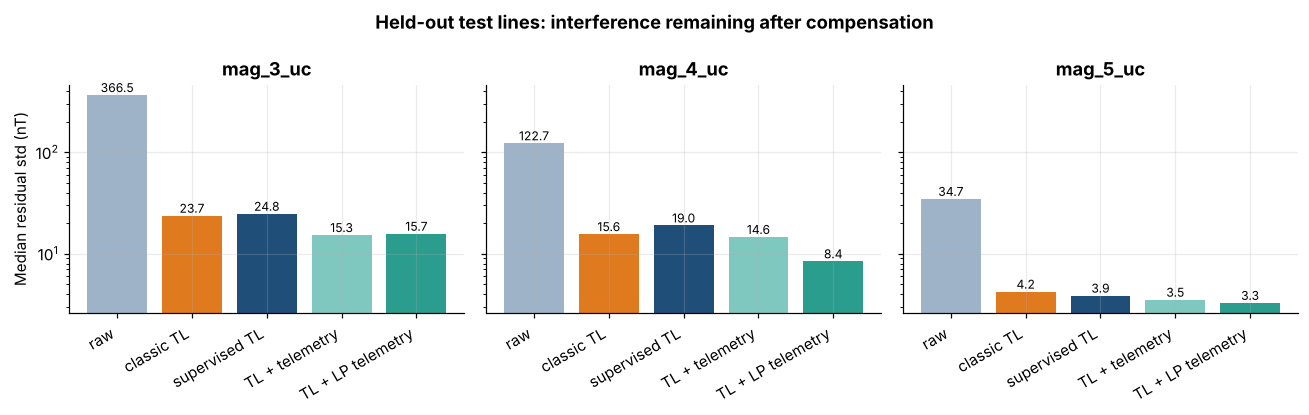

In [6]:
aux = [k for k in D if k.startswith(("cur_", "vol_"))] + ["ins_roll", "ins_pitch", "roll_rt", "pitch_rt", "yaw_rt"]
tr = np.isin(line, TRAIN)
Z = np.stack([D[k] for k in aux], 1)
Z = (Z - Z[tr].mean(0)) / (Z[tr].std(0) + 1e-9)
from scipy import signal
Zlp = signal.sosfiltfilt(signal.butter(4, 0.5, fs=10, output="sos"), Z, axis=0)

def fit_predict(X, y, lam):
    coef = np.linalg.solve(X[tr].T @ X[tr] + lam*np.eye(X.shape[1]), X[tr].T @ y[tr])
    return X @ coef

results, comp = {}, {}
for m in MAGS:
    y = D[m] - D["mag_1_c"]
    A = q.tl_matrix(*(D[f"flux_b_{a}"] for a in "xyz"))
    X1 = np.c_[A, np.ones(len(y))]
    comp[(m, "TL")] = D[m] - fit_predict(X1, y, 0.0)
    comp[(m, "TL+aux")] = D[m] - fit_predict(np.c_[X1, Z], y, 1.0)
    comp[(m, "TL+auxLP")] = D[m] - fit_predict(np.c_[X1, Zlp], y, 1.0)
    results[m] = {"raw": raw[m],
                  "classic TL": [resid(classic[(m, "b")], l) for l in TEST],
                  "supervised TL": [resid(comp[(m, "TL")], l) for l in TEST],
                  "TL + telemetry": [resid(comp[(m, "TL+aux")], l) for l in TEST],
                  "TL + LP telemetry": [resid(comp[(m, "TL+auxLP")], l) for l in TEST]}

fig, ax = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for a, m in zip(ax, MAGS):
    labels = list(results[m])
    vals = [np.median(results[m][k]) for k in labels]
    bars = a.bar(range(5), vals, color=["#9fb3c8", "#e07a1f", "#1f4e79", "#7fc8bf", "#2a9d8f"])
    a.bar_label(bars, fmt="%.1f", fontsize=8)
    a.set_xticks(range(5), labels, rotation=30, ha="right"); a.set_title(m); a.set_yscale("log")
ax[0].set_ylabel("Median residual std (nT)")
fig.suptitle("Held-out test lines: interference remaining after compensation", fontweight="bold")
plt.tight_layout()

In [7]:
for m in MAGS:
    r = {k: np.median(v) for k, v in results[m].items()}
    print(f"{m}: raw {r['raw']:6.1f} | classic TL {r['classic TL']:5.1f} | TL+LP telemetry {r['TL + LP telemetry']:5.1f} nT"
          f"   ({100*(1-r['TL + LP telemetry']/r['raw']):.0f}% total reduction)")

mag_3_uc: raw  366.5 | classic TL  23.7 | TL+LP telemetry  15.7 nT   (96% total reduction)
mag_4_uc: raw  122.7 | classic TL  15.6 | TL+LP telemetry   8.4 nT   (93% total reduction)
mag_5_uc: raw   34.7 | classic TL   4.2 | TL+LP telemetry   3.3 nT   (91% total reduction)


## 5. What is left? A spectral view

Amplitude spectral density of the residual on test line 1367 shows *where* in frequency the remaining interference lives, and exposes a trap.

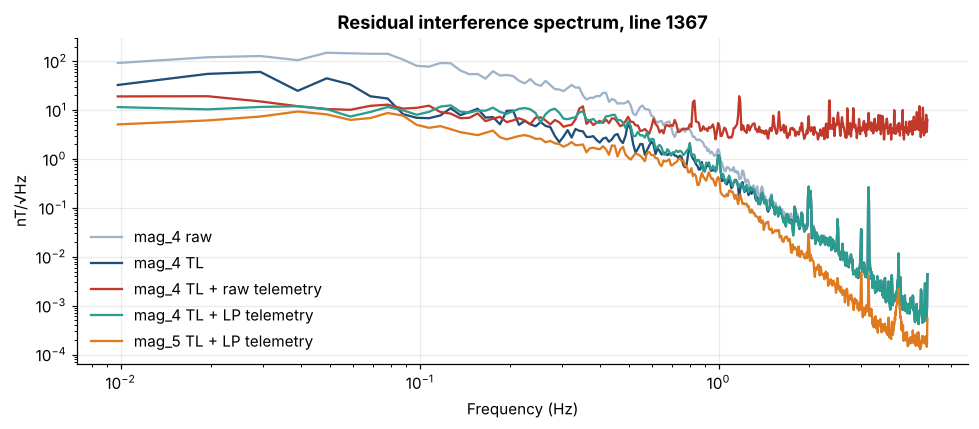

In [8]:
s = line == 1367
fig, ax = plt.subplots(figsize=(9, 4))
for lab, sig, c in [("mag_4 raw", D["mag_4_uc"], "#9fb3c8"), ("mag_4 TL", comp[("mag_4_uc", "TL")], "#1f4e79"),
                    ("mag_4 TL + raw telemetry", comp[("mag_4_uc", "TL+aux")], "#c0392b"),
                    ("mag_4 TL + LP telemetry", comp[("mag_4_uc", "TL+auxLP")], "#2a9d8f"),
                    ("mag_5 TL + LP telemetry", comp[("mag_5_uc", "TL+auxLP")], "#e07a1f")]:
    f, a = q.psd(sig[s] - D["mag_1_c"][s])
    ax.loglog(f[1:], a[1:], label=lab, c=c)
ax.set(xlabel="Frequency (Hz)", ylabel="nT/√Hz", title="Residual interference spectrum, line 1367")
ax.legend(); plt.tight_layout()

Raw telemetry channels are noisy and quantised. Regressing on them lowers the low-frequency error but **injects broadband noise above ~0.5 Hz** (red curve, ~4 nT/√Hz) — exactly the band a MAD or fine-scale survey cares about. Low-passing the regressors before fitting keeps the low-frequency gain and leaves the high band clean.

## Conclusions

* **Sensor placement matters more than the algorithm.** `mag_5` starts ~10× cleaner than `mag_3` and stays the best sensor after every method. On a new installation, an interference survey to choose the mount point pays for itself.
* **Classic Tolles–Lawson is a strong baseline**, even when the calibration box is flown 3 km above the survey: ~85–95 % of in-cabin interference is removed.
* **What remains is mostly slow (< 0.1 Hz)** and comes from sources outside the TL physics. Aircraft telemetry explains part of it: a 53-parameter linear model cuts `mag_4`'s residual from ~16 to ~8 nT.
* **Filter your regressors.** Feeding raw telemetry into a compensation model (linear or neural) can quietly add noise at the frequencies you care about. Check the residual spectrum, not just the RMS.
* The best in-cabin residual here (~3 nT) is adequate for magnetic navigation over a well-mapped area — see Notebook 02.

### References

[1] A. R. Gnadt *et al.*, "DAF-MIT AIA open flight data for magnetic navigation research," Zenodo, 2023, doi: 10.5281/zenodo.4271803.  
[2] W. E. Tolles and J. D. Lawson, "Magnetic compensation of MAD equipped aircraft," Airborne Instruments Lab. Inc., Mineola, NY, USA, Rep. 201-1, 1950.  
[3] A. R. Gnadt *et al.*, "Signal enhancement for magnetic navigation challenge problem," arXiv:2007.12158, 2020.

---
© QuASI Inc. · Code MIT-licensed · Data in the public domain (17 U.S.C. 105).